# BAFAD Week 4 — Exercise 1: Batch SKAB Contamination Pipeline

**Name:** Jaylin Quinn  
**Week:** 4 · Oct 19–25, 2026  
**Commit message:** `feat: build batch SKAB contamination pipeline`  
**Objective:** Build a batch pipeline that processes all files in a SKAB-format directory,
saves contaminated arrays, and generates a contamination catalog.

---

## Section 1: Setup & Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import ast

print(f'NumPy   version: {np.__version__}')
print(f'pandas  version: {pd.__version__}')
print('Imports successful.')

NumPy   version: 2.1.3
pandas  version: 2.2.3
Imports successful.


## Section 2: Carry-Forward Functions from Weeks 2–3

Run this cell as-is. These functions are unchanged from previous weeks.

In [2]:
def extract_anomaly_windows(anomaly_labels):
    """Converts binary label array to list of (start, end) tuples."""
    windows   = []
    in_window = False
    start     = 0
    for i, label in enumerate(anomaly_labels):
        if label == 1 and not in_window:
            start     = i
            in_window = True
        elif label == 0 and in_window:
            windows.append((start, i))
            in_window = False
    if in_window:
        windows.append((start, len(anomaly_labels)))
    return windows


def inject_noise_profile(raw_data, start_idx, end_idx, variance=2.5, mode='noise'):
    """Injects noise or blackout into a localized index window."""
    poisoned_data = raw_data.copy()
    window_rows   = end_idx - start_idx
    n_features    = poisoned_data.shape[1]
    if mode == 'noise':
        injection = np.random.normal(0, variance, size=(window_rows, n_features))
        poisoned_data[start_idx:end_idx, :] += injection
    elif mode == 'blackout':
        poisoned_data[start_idx:end_idx, :] = 0.0
    else:
        raise ValueError(f"Unknown mode: '{mode}'.")
    return poisoned_data


print('Carry-forward functions loaded.')

Carry-forward functions loaded.


## Section 3: Generate Synthetic SKAB-Format Dataset

This section creates a local `synthetic_alldata/` directory with 5 CSV files in SKAB format.
When you run this notebook with the real SKAB data in Colab, replace `DATA_DIR = Path('synthetic_alldata')`
with `DATA_DIR = Path('SKAB/alldata')` in Section 4 — no other changes needed.

Run this cell as-is.

In [3]:
def make_synthetic_skab_file(filepath, n_rows, anomaly_windows, seed=0):
    """
    Generates a synthetic SKAB-format CSV with 8 sensor columns,
    an anomaly label column, and a changepoint column.
    """
    np.random.seed(seed)
    t       = np.linspace(0, 50, n_rows)
    sensors = {}
    names   = ['Accelerometer1RMS', 'Accelerometer2RMS', 'Current',
                'Pressure', 'Temperature', 'Thermocouple',
                'Voltage', 'Volume Flow RateRMS']
    for i, name in enumerate(names):
        sensors[name] = np.sin(t * (i + 1)) + np.random.normal(0, 0.05, n_rows)

    labels      = np.zeros(n_rows, dtype=int)
    changepoint = np.zeros(n_rows, dtype=int)
    for s, e in anomaly_windows:
        labels[s:e]    = 1
        changepoint[s] = 1

    idx = pd.date_range('2020-01-01', periods=n_rows, freq='1s')
    df  = pd.DataFrame(sensors, index=idx)
    df.index.name = 'datetime'
    df['anomaly']     = labels
    df['changepoint'] = changepoint
    df.to_csv(filepath, sep=';')


# Create synthetic dataset: 5 files, varying lengths and anomaly profiles
synth_dir = Path('synthetic_alldata')
synth_dir.mkdir(exist_ok=True)

files_spec = [
    ('1.csv', 800,  [(150, 230), (500, 580)]),
    ('2.csv', 1000, [(200, 350)]),
    ('3.csv', 600,  []),
    ('4.csv', 900,  [(100, 160), (400, 480), (700, 750)]),
    ('5.csv', 750,  [(300, 420)]),
]

for fname, n_rows, windows in files_spec:
    make_synthetic_skab_file(synth_dir / fname, n_rows, windows)

actual = sorted(synth_dir.glob('*.csv'))
print(f'Generated {len(actual)} synthetic SKAB files in {synth_dir}/')
for f in actual:
    df = pd.read_csv(f, sep=';', index_col='datetime')
    n_anom = df['anomaly'].sum()
    print(f'  {f.name}: {len(df)} rows, {n_anom} anomaly rows')

Generated 5 synthetic SKAB files in synthetic_alldata/
  1.csv: 800 rows, 160 anomaly rows
  2.csv: 1000 rows, 150 anomaly rows
  3.csv: 600 rows, 0 anomaly rows
  4.csv: 900 rows, 190 anomaly rows
  5.csv: 750 rows, 120 anomaly rows


## Section 4: Implement `process_skab_file()`

The single-file processing function. Loads one SKAB CSV, extracts anomaly windows,
injects a noise profile, and returns results + metadata.

**Your task:** Complete the function body. The docstring describes the expected return dict.

In [7]:
def process_skab_file(filepath, mode='noise', variance=2.5, seed=42):
    """
    Loads one SKAB CSV, extracts anomaly windows, injects a noise profile,
    and returns the contaminated sensor array with metadata.

    Parameters
    ----------
    filepath : Path or str
    mode     : str — 'noise' or 'blackout'
    variance : float — std dev for mode='noise'
    seed     : int — random seed for reproducibility

    Returns
    -------
    dict with keys: filename, X_clean, X_contaminated, windows,
                    n_windows, n_rows, n_features
    """


    df = pd.read_csv(filepath, sep=';', index_col='datetime', parse_dates=True)

    sensor_df = df.drop(columns=['anomaly', 'changepoint'])
    X = sensor_df.to_numpy(dtype=float)
    labels = df['anomaly'].to_numpy(dtype=int)

    windows = extract_anomaly_windows(labels)

    np.random.seed(seed)
    X_contaminated = X.copy()

    for start, end in windows:
        X_contaminated = inject_noise_profile(
            X_contaminated, start, end, variance=variance, mode=mode
        )

    return {
        'filename': Path(filepath).name,
        'X_clean': X,
        'X_contaminated': X_contaminated,
        'windows': windows,
        'n_windows': len(windows),
        'n_rows': X.shape[0],
        'n_features': X.shape[1]
    }


# Test on one file before running the full batch
test_result = process_skab_file(synth_dir / '1.csv', mode='noise', variance=2.5, seed=42)
print(f"filename    : {test_result['filename']}")
print(f"X_clean     : shape={test_result['X_clean'].shape}")
print(f"X_cont      : shape={test_result['X_contaminated'].shape}")
print(f"windows     : {test_result['windows']}")
print(f"n_windows   : {test_result['n_windows']}")

# Verify: outside-window rows unchanged, inside-window rows differ
assert np.array_equal(test_result['X_contaminated'][:150], test_result['X_clean'][:150])
assert not np.array_equal(test_result['X_contaminated'][150:230], test_result['X_clean'][150:230])
print('Single-file assertions passed.')

filename    : 1.csv
X_clean     : shape=(800, 8)
X_cont      : shape=(800, 8)
windows     : [(150, 230), (500, 580)]
n_windows   : 2
Single-file assertions passed.


## Section 5: Implement `batch_inject()`

The batch loop: processes all CSV files in a directory, saves contaminated arrays,
and returns a contamination catalog DataFrame.

**Your task:** Complete the function body.

In [8]:
def batch_inject(data_dir, output_dir, mode='noise', variance=2.5, seed=42):
    """
    Processes all CSV files in data_dir, saves contaminated arrays to output_dir,
    and returns a contamination catalog as a DataFrame.

    Parameters
    ----------
    data_dir   : Path or str
    output_dir : Path or str
    mode       : str — 'noise' or 'blackout'
    variance   : float
    seed       : int

    Returns
    -------
    catalog : pd.DataFrame — one row per processed file
    """

    data_dir = Path(data_dir)
    output_dir = Path(output_dir)
    output_dir.mkdir(exist_ok=True)

    csv_files = sorted(data_dir.glob('*.csv'))
    print(f"Found {len(csv_files)} CSV files.")

    records = []

    for filepath in csv_files:
        result = process_skab_file(
            filepath, mode=mode, variance=variance, seed=seed
        )

        output_path = output_dir / result['filename']
        pd.DataFrame(result['X_contaminated']).to_csv(
            output_path, index=False
        )

        records.append({
            'filename': result['filename'],
            'mode': mode,
            'variance': variance if mode == 'noise' else None,
            'seed': seed,
            'n_rows': result['n_rows'],
            'n_features': result['n_features'],
            'n_windows': result['n_windows'],
            'windows': str(result['windows'])
        })

    catalog = pd.DataFrame(records)
    return catalog


# Run the batch pipeline
DATA_DIR   = Path('synthetic_alldata')   # swap to Path('SKAB/alldata') for real data
OUTPUT_DIR = Path('contaminated')

catalog = batch_inject(DATA_DIR, OUTPUT_DIR, mode='noise', variance=2.5, seed=42)
catalog.to_csv('contamination_catalog.csv', index=False)

print()
print(catalog[['filename', 'n_rows', 'n_windows', 'windows']].to_string(index=False))

Found 5 CSV files.

filename  n_rows  n_windows                              windows
   1.csv     800          2             [(150, 230), (500, 580)]
   2.csv    1000          1                         [(200, 350)]
   3.csv     600          0                                   []
   4.csv     900          3 [(100, 160), (400, 480), (700, 750)]
   5.csv     750          1                         [(300, 420)]


## Section 6: Verify the Catalog and Output Files

Run this cell as-is. All assertions must pass.

In [9]:
# Catalog shape and column check
assert len(catalog) == 5, f'Expected 5 rows, got {len(catalog)}'
assert set(['filename','mode','variance','seed','n_rows','n_features','n_windows','windows']).issubset(set(catalog.columns))

# File 3.csv has no anomalies — n_windows should be 0
row_3 = catalog[catalog['filename'] == '3.csv'].iloc[0]
assert row_3['n_windows'] == 0, f"Expected 0 windows for 3.csv, got {row_3['n_windows']}"

# Verify output files exist and have correct shape
for _, row in catalog.iterrows():
    out_path = OUTPUT_DIR / row['filename']
    assert out_path.exists(), f'Missing output file: {out_path}'
    reloaded = pd.read_csv(out_path).values
    assert reloaded.shape == (row['n_rows'], row['n_features']), \
        f"{row['filename']}: shape mismatch {reloaded.shape}"

# Files with windows: outside-window rows must match original
for _, row in catalog[catalog['n_windows'] > 0].iterrows():
    result    = process_skab_file(DATA_DIR / row['filename'], mode='noise', variance=2.5, seed=42)
    reloaded  = pd.read_csv(OUTPUT_DIR / row['filename']).values
    first_window_start = ast.literal_eval(row['windows'])[0][0]
    if first_window_start > 50:
        assert np.allclose(reloaded[:50], result['X_clean'][:50])

modified = catalog[catalog['n_windows'] > 0]
print(f'{len(modified)} / {len(catalog)} files contained anomaly windows')
print(f'3.csv correctly has n_windows=0 (clean run)')
print('All catalog and output file assertions passed.')

4 / 5 files contained anomaly windows
3.csv correctly has n_windows=0 (clean run)
All catalog and output file assertions passed.


## Section 7: Visualization — One File Before and After

Plot `4.csv` (3 windows) to show the effect of noise injection.

**Your task:** Fill in the TODO items to complete the two-panel plot.

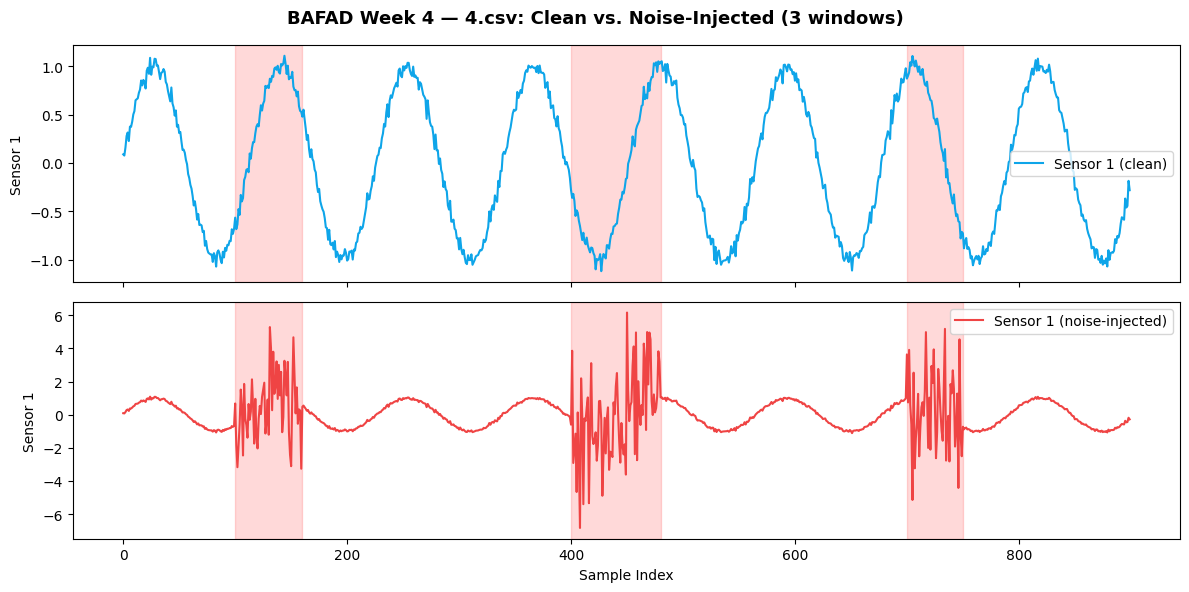

Plot saved to week04_exercise1_plot.png


In [10]:
# Process 4.csv for plotting
result_4 = process_skab_file(DATA_DIR / '4.csv', mode='noise', variance=2.5, seed=42)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
t = np.arange(result_4['n_rows'])


axes[0].plot(t, result_4['X_clean'][:, 0],
             color='#0EA5E9', label='Sensor 1 (clean)')

axes[1].plot(t, result_4['X_contaminated'][:, 0],
             color='#EF4444', label='Sensor 1 (noise-injected)')

for start, end in result_4['windows']:
    for ax in axes:
        ax.axvspan(start, end, alpha=0.15, color='red')

axes[0].set_ylabel('Sensor 1')
axes[1].set_ylabel('Sensor 1')
axes[1].set_xlabel('Sample Index')

axes[0].legend()
axes[1].legend()


fig.suptitle('BAFAD Week 4 — 4.csv: Clean vs. Noise-Injected (3 windows)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('week04_exercise1_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved to week04_exercise1_plot.png')

## Section 8: Interpretation Questions

Answer each question in 2–4 sentences.

**Q1.** The pipeline calls `np.random.seed(seed)` inside `process_skab_file()` rather than once
before the batch loop. Why does this matter? What would change if the seed were set once
globally before the loop?

> *[Setting the seed inside the function makes sure we get the same results every time we run a file. If we only set it once before the loop the results could change depending on the order the files are processed. I think keeping it inside the function makes it easier to test things and get consistent results.]*

**Q2.** The catalog shows `n_windows=0` for `3.csv`. Should this file be excluded from anomaly
detection evaluation? Explain both sides.

> *[I don't think we should exclude 3.csv just because it doesn't have any anomalies. Even though it won't help us see how well the model detects anomalies, it can still show us if the model is incorrectly detecting problems that aren't actually there. I think it's important to test both normal and abnormal data to get a better idea of how accurate the model is.]*

**Q3.** A colleague runs `batch_inject()` again with `mode='blackout'` and saves the catalog as
`contamination_catalog_blackout.csv`. How would you merge the two catalogs into one DataFrame
that shows both modes for each file?

> *[I would use pandas to load both CSV files and combine them into one DataFrame using pd.concat(). Since each file already has a filename and mode we would still be able to tell which results came from noise injection and which came from blackout. This would make it easier to compare the results and see how each method affects the same files.]*

## Section 9: Git Commit

```bash
git add week04/BAFAD_Week04_Exercise1.ipynb
git add week04/contamination_catalog.csv
git commit -m "feat: build batch SKAB contamination pipeline"
git push origin main
```